# Ejercicio 2 - Pandas, NumPy y Matplotlib
Dataset: Pingüinos de Palmer (Palmer Penguins)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# URL del dataset de pingüinos de Palmer
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv'

# Cargar los datos
df = pd.read_csv(url)

# Mostrar los primeros registros para confirmar
print('Dataset cargado correctamente:')
df.head()

Dataset cargado correctamente:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## Ejercicio 2.1 - Análisis Exploratorio con Pandas

### 2.1.2 Manejo de nulos

In [3]:
print('Forma original:', df.shape)
print()
print('Nulos por columna:')
print(df.isna().sum())
print()
print('Filas con al menos un NaN:', df.isna().any(axis=1).sum())

Forma original: (344, 7)

Nulos por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Filas con al menos un NaN: 11


In [4]:
# Eliminar filas donde falten datos críticos (peso y medidas del pico/aleta)
criticas = ['body_mass_g', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']
df_clean = df.dropna(subset=criticas).reset_index(drop=True)

print('Forma después de limpiar:', df_clean.shape)
print('Filas eliminadas:', len(df) - len(df_clean))
print('Nulos restantes (la columna sex no es crítica):')
print(df_clean.isna().sum())

Forma después de limpiar: (342, 7)
Filas eliminadas: 2
Nulos restantes (la columna sex no es crítica):
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


### 2.1.3 Agrupación: masa corporal promedio por especie e isla

In [5]:
masa_prom = df_clean.groupby(['species', 'island'])['body_mass_g'].mean().round(2)
masa_prom

species    island   
Adelie     Biscoe       3709.66
           Dream        3688.39
           Torgersen    3706.37
Chinstrap  Dream        3733.09
Gentoo     Biscoe       5076.02
Name: body_mass_g, dtype: float64

### 2.1.4 Segmentación: Gentoo con más de 5000 g

In [6]:
gentoo_pesados = df_clean[(df_clean['species'] == 'Gentoo') & (df_clean['body_mass_g'] > 5000)]
print('Gentoo con más de 5000 g:', len(gentoo_pesados))
gentoo_pesados.head()

Gentoo con más de 5000 g: 61


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
220,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE
222,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE
223,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
226,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,MALE
228,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,MALE


## Ejercicio 2.2 - Procesamiento de señales con NumPy

### 2.2.1 Matriz N x 2 (largo y alto del pico)

In [7]:
X = df_clean[['bill_length_mm', 'bill_depth_mm']].to_numpy()
print('Forma de X:', X.shape)
print(X[:5])

Forma de X: (342, 2)
[[39.1 18.7]
 [39.5 17.4]
 [40.3 18. ]
 [36.7 19.3]
 [39.3 20.6]]


### 2.2.2 Proporción largo / alto

In [8]:
proporcion = X[:, 0] / X[:, 1]
print('Forma:', proporcion.shape)
print('Primeros 5 valores:', proporcion[:5].round(3))
print('Mín: %.3f  Máx: %.3f  Media: %.3f' % (proporcion.min(), proporcion.max(), proporcion.mean()))

Forma: (342,)
Primeros 5 valores: [2.091 2.27  2.239 1.902 1.908]
Mín: 1.640  Máx: 3.613  Media: 2.606


### 2.2.3 Outliers: largo de pico a más de 2 desviaciones estándar de la media

In [15]:
largo = X[:, 0]
media = np.mean(largo)
desv = np.std(largo)
print(len(X))
# Índices de los pingüinos outliers
idx_outliers = np.where(np.abs(largo - media) > 2 * desv)[0]

print('Media: %.2f mm | Desv. estándar: %.2f mm' % (media, desv))
print('Rango normal: [%.2f, %.2f]' % (media - 2 * desv, media + 2 * desv))
print('Número de outliers:', len(idx_outliers))
print('Índices:', idx_outliers)
df_clean.loc[idx_outliers, ['species', 'island', 'bill_length_mm']]

342
Media: 43.92 mm | Desv. estándar: 5.45 mm
Rango normal: [33.02, 54.83]
Número de outliers: 6
Índices: [141 168 214 252 320 334]


,species,island,bill_length_mm
141,Adelie,Dream,32.1
168,Chinstrap,Dream,58.0
214,Chinstrap,Dream,55.8
252,Gentoo,Biscoe,59.6
320,Gentoo,Biscoe,55.9
334,Gentoo,Biscoe,55.1


### 2.2.4 Slicing: posiciones pares del array original

In [10]:
pares = X[::2]   # posiciones 0, 2, 4, ...
print('Forma original:', X.shape, '-> posiciones pares:', pares.shape)
print(pares[:5])

Forma original: (342, 2) -> posiciones pares: (171, 2)
[[39.1 18.7]
 [40.3 18. ]
 [39.3 20.6]
 [39.2 19.6]
 [42.  20.2]]


## Ejercicio 2.3 - Visualización científica con Matplotlib

### 2.3.1 - 2.3.3 Scatter plot por especie con anotación del pingüino más pesado

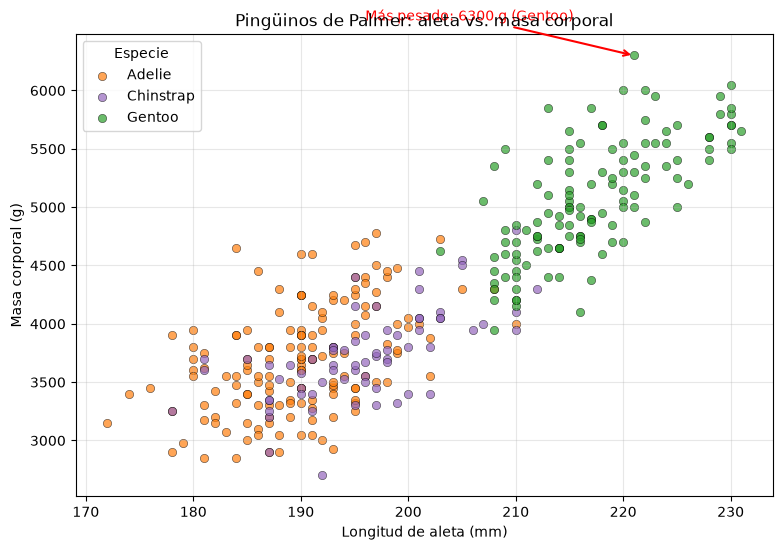

In [11]:
colores = {'Adelie': 'tab:orange', 'Chinstrap': 'tab:purple', 'Gentoo': 'tab:green'}

fig, ax = plt.subplots(figsize=(9, 6))

for especie, color in colores.items():
    sub = df_clean[df_clean['species'] == especie]
    ax.scatter(sub['flipper_length_mm'], sub['body_mass_g'],
               c=color, label=especie, alpha=0.7, edgecolors='k', linewidths=0.4)

# Pingüino más pesado
i_max = df_clean['body_mass_g'].idxmax()
p = df_clean.loc[i_max]
ax.annotate('Más pesado: %d g (%s)' % (p['body_mass_g'], p['species']),
            xy=(p['flipper_length_mm'], p['body_mass_g']),
            xytext=(p['flipper_length_mm'] - 25, p['body_mass_g'] + 300),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
            fontsize=10, color='red')

ax.set_xlabel('Longitud de aleta (mm)')
ax.set_ylabel('Masa corporal (g)')
ax.set_title('Pingüinos de Palmer: aleta vs. masa corporal')
ax.legend(title='Especie')
ax.grid(alpha=0.3)
plt.show()

### 2.3.4 Layout con dos subplots: masa corporal y longitud de aleta por especie

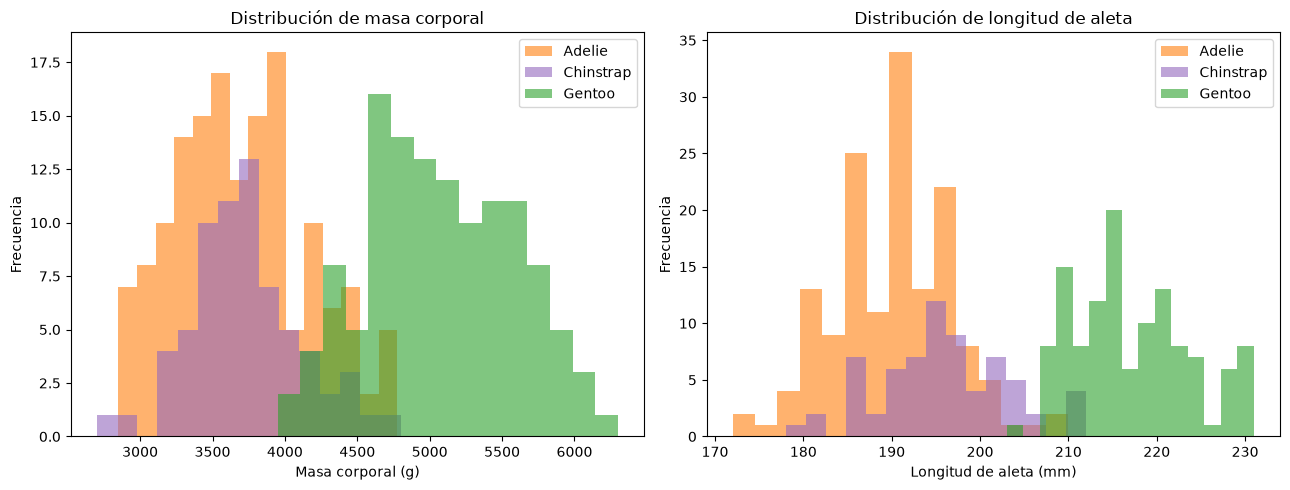

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for especie, color in colores.items():
    sub = df_clean[df_clean['species'] == especie]
    ax1.hist(sub['body_mass_g'], bins=15, alpha=0.6, color=color, label=especie)
    ax2.hist(sub['flipper_length_mm'], bins=15, alpha=0.6, color=color, label=especie)

ax1.set_title('Distribución de masa corporal')
ax1.set_xlabel('Masa corporal (g)')
ax1.set_ylabel('Frecuencia')
ax1.legend()

ax2.set_title('Distribución de longitud de aleta')
ax2.set_xlabel('Longitud de aleta (mm)')
ax2.set_ylabel('Frecuencia')
ax2.legend()

plt.tight_layout()
plt.show()